# Задание 2.9*
## Множества Жюлиа

### Условие:
в) Написать программу (Jupyter Notebook), строящую множество Жюлиа отображения $f_c(z)=z^2+c$ для $c=-0{,}1+0{,}65i$ и $c=0{,}28+0{,}009i$.
г) Написать программу, строящую множества Жюлиа для $f(z)=\dfrac{iz^5-1}{z^5-i}$ и $f(z)=\dfrac{z^2+i}{1-z^2}$.

### Теория (пункты а, б):
Для отображения $f:\widehat{\mathbb C}\to\widehat{\mathbb C}$ рассматривают итерации $z_{n+1}=f(z_n)$. Для $f_c(z)=z^2+c$ заполненное множество Жюлиа $K_c$ — это множество начальных точек $z_0$, у которых орбита ограничена; множество Жюлиа $J_c=\partial K_c$ — его граница. Если $|z_n|>\max(2,|c|)$ для некоторого $n$, то $|z_n|\to\infty$, поэтому достаточно итерировать, пока $|z|\le R$ или пока не исчерпано число шагов $N$.

**Алгоритм (метод времени убегания).** Для каждой точки $z_0$ сетки в окне $[x_{\min},x_{\max}]\times[y_{\min},y_{\max}]$ считаем число итераций $n$ до выхода из круга $|z|\le R$ ($R=10$, $N=1000$ — как в образце) и красим пиксель по значению $n/N$. Точки с $n/N=1$ — приближение к $K_c$. Для вычислений на 250 тысячах пикселей используем векторизацию `numpy`, а не двойной цикл.

In [3]:
import numpy as np
import matplotlib.pyplot as plt

def julia_set(f, lim, n=500, nit_max=1000, zabs_max=10):
    '''доля nit/nit_max для сетки n×n в окне [−lim, lim]²; f действует на массив complex'''
    xs = np.linspace(-lim, lim, n)
    X, Y = np.meshgrid(xs, xs)
    z = X + 1j*Y
    nit = np.zeros(z.shape, dtype=int)
    alive = np.ones(z.shape, dtype=bool)
    with np.errstate(all='ignore'):                      # деление на 0 даёт inf/nan — такие точки «вышли»
        for _ in range(nit_max):
            z = np.where(alive, f(z), z)
            alive &= np.abs(z) <= zabs_max               # nan → False
            nit += alive
            if not alive.any():
                break
    return nit/nit_max

def show(julia, lim, title, cmap='flag'):
    fig, ax = plt.subplots(figsize=(6.5, 6.5))
    ax.imshow(julia, cmap=cmap, extent=[-lim, lim, -lim, lim], origin='lower')
    ax.set_title(title)
    ax.set_xlabel('Re z'); ax.set_ylabel('Im z')
    plt.show()

### Принадлежность параметров множеству Мандельброта
Множество $J_c$ связно тогда и только тогда, когда орбита нуля $0,c,c^2+c,\dots$ ограничена.

In [4]:
for c in (-0.1 + 0.65j, 0.28 + 0.009j):
    z, k = 0j, 0
    while abs(z) <= 2 and k < 10000:
        z = z*z + c
        k += 1
    print(f'c = {c}:  орбита нуля вышла из круга |z|≤2 на шаге {k}' if abs(z) > 2 else f'c = {c}: орбита ограничена')
    s = np.sqrt(1 - 4*c)                       # неподвижные точки: z^2 − z + c = 0
    for zf in ((1 + s)/2, (1 - s)/2):
        print(f'      неподвижная точка {zf:.4f},  |f\'(z)| = |2z| = {abs(2*zf):.5f}')

c = (-0.1+0.65j):  орбита нуля вышла из круга |z|≤2 на шаге 75
      неподвижная точка 1.2376-0.4406j,  |f'(z)| = |2z| = 2.62746
      неподвижная точка -0.2376+0.4406j,  |f'(z)| = |2z| = 1.00119
c = (0.28+0.009j):  орбита нуля вышла из круга |z|≤2 на шаге 58
      неподвижная точка 0.5257-0.1751j,  |f'(z)| = |2z| = 1.10819
      неподвижная точка 0.4743+0.1751j,  |f'(z)| = |2z| = 1.01118


### в) $f_c(z)=z^2+c$, $c=-0{,}1+0{,}65i$

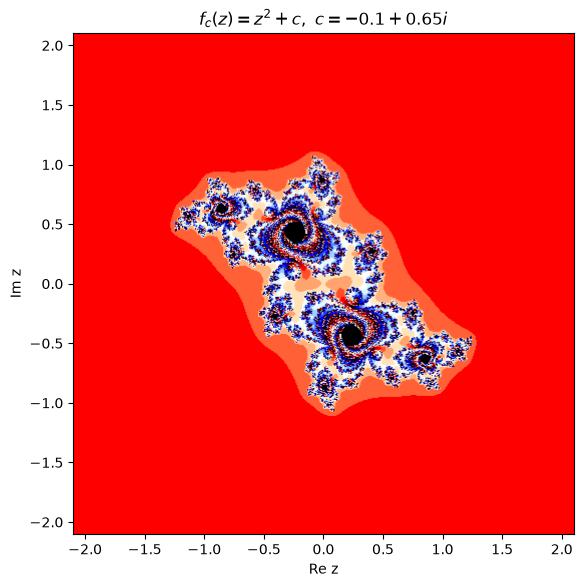

In [5]:
c1 = complex(-0.1, 0.65)
J1 = julia_set(lambda z: z*z + c1, lim=2.1)
show(J1, 2.1, r'$f_c(z)=z^2+c,\ c=-0.1+0.65i$')

### в) $f_c(z)=z^2+c$, $c=0{,}28+0{,}009i$

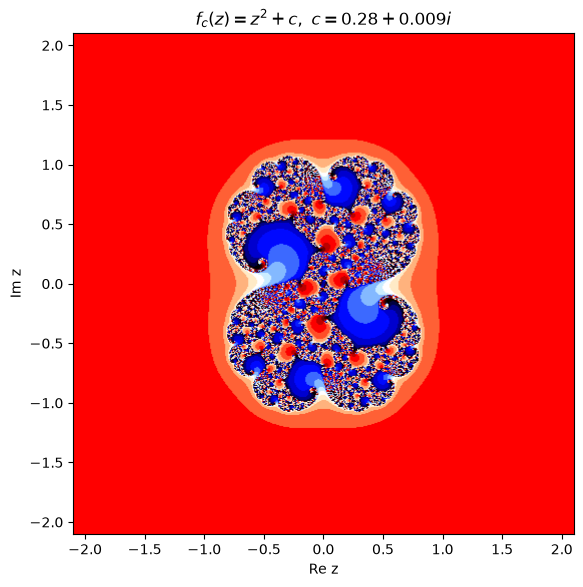

In [6]:
c2 = complex(0.28, 0.009)
J2 = julia_set(lambda z: z*z + c2, lim=2.1)
show(J2, 2.1, r'$f_c(z)=z^2+c,\ c=0.28+0.009i$')

### г) $f(z)=\dfrac{iz^5-1}{z^5-i}$

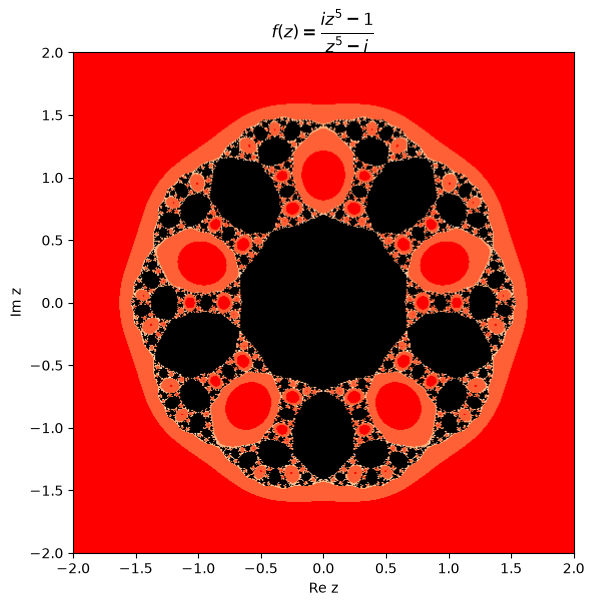

In [7]:
f3 = lambda z: (1j*z**5 - 1)/(z**5 - 1j)
J3 = julia_set(f3, lim=2.0)
show(J3, 2.0, r'$f(z)=\dfrac{iz^5-1}{z^5-i}$')

### г) $f(z)=\dfrac{z^2+i}{1-z^2}$

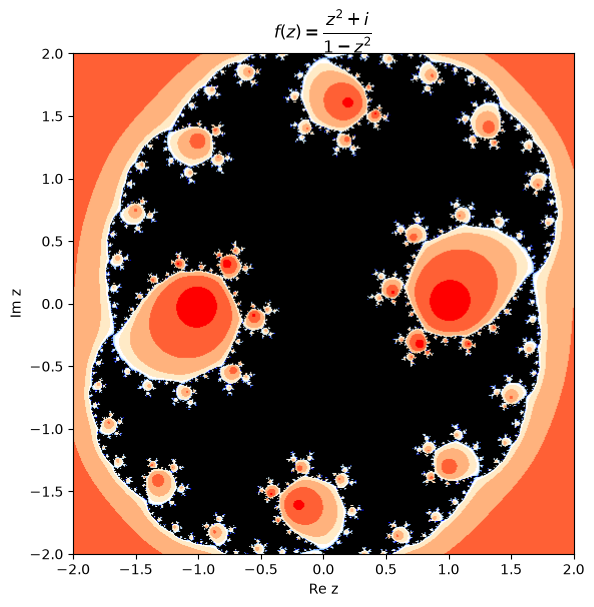

In [8]:
f4 = lambda z: (z*z + 1j)/(1 - z*z)
J4 = julia_set(f4, lim=2.0)
show(J4, 2.0, r'$f(z)=\dfrac{z^2+i}{1-z^2}$')

### Выводы:

- Для $c=-0{,}1+0{,}65i$ и $c=0{,}28+0{,}009i$ орбита нуля уходит на бесконечность, значит, $c\notin M$ и $J_c$ несвязно (канторова «пыль»). Параметры лежат очень близко к границе множества Мандельброта: у $f_c$ есть неподвижная точка с $|f_c'(z)|$ чуть больше $1$ (см. вывод ячейки выше), поэтому орбиты точек рядом с ней уходят на бесконечность очень медленно. «Чёрные» области рисунка — это точки, не вышедшие из круга за 1000 шагов; при увеличении `nit_max` они уменьшаются.
- Для рациональных отображений в $\widehat{\mathbb C}$ бесконечность не обязана быть притягивающей, поэтому «убегание» из круга $|z|\le10$ означает близость к полюсу или к бесконечности; рисунки показывают структуру, на которую влияют полюсы и прообразы бесконечности. Симметрия первого отображения (5-го порядка) следует из того, что $f(z)$ зависит только от $z^5$.
- Код одинаков для всех случаев: меняется только функция `f` и окно `lim`.